Original database: (13494, 39)
Number of features: 37
Features removed: 8
['wtd_gmean_atomic_weight', 'wtd_gmean_ionenergies', 'wtd_gmean_atomic_radius', 'wtd_variance_atomic_radius', 'wtd_gmean_electron_affinity', 'wtd_gmean_fusion_heat', 'cu_transition_ratio', 'atomic_radius_mismatch']
Final Pearson database: (13494, 31)
Completed


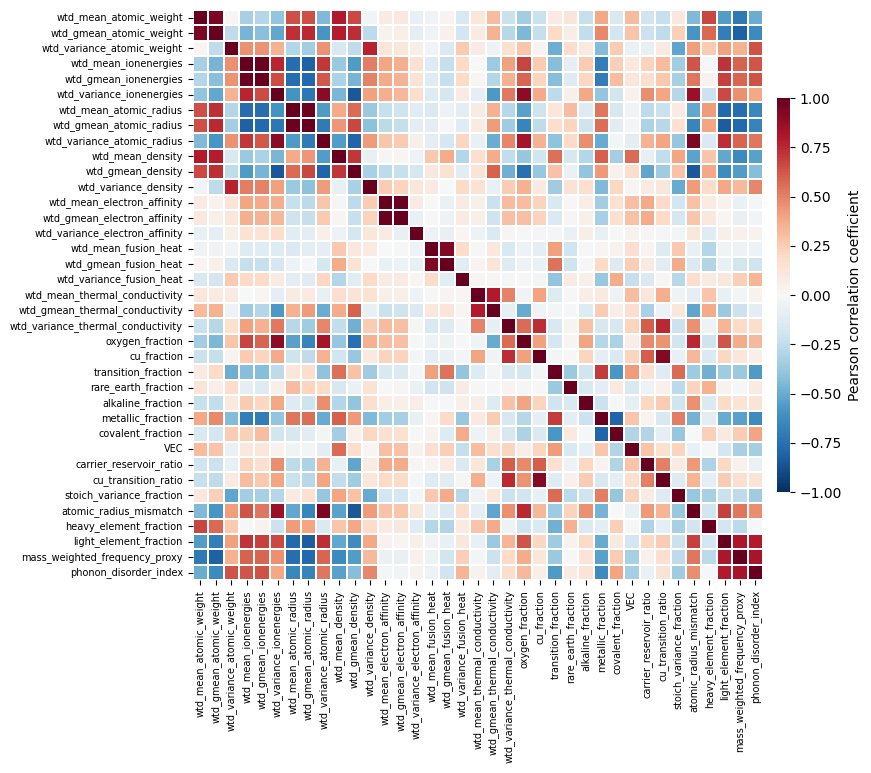

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_excel("Features_37_13494.xlsx")
print("Original database:",df.shape)

target = "Temp"

id_columns = ["Material", "Temp"]

features = df.drop(columns=id_columns)

print("Number of features:",features.shape[1])

corr_matrix = features.corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 8))

sns.heatmap(
    corr_matrix,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    annot=False,
    linewidths=0.25,
    cbar_kws={
    "label": "Pearson correlation coefficient",
    "shrink": 0.65,   # Length: 65% of the heatmap height
    "aspect": 30,     # Larger value makes the bar thinner
    "pad": 0.02       # Gap between heatmap and colorbar
},
    ax=ax
)

plt.setp(ax.get_xticklabels(), rotation=90, fontsize=7)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=7)
fig.tight_layout()

fig.savefig("Heatmap.pdf",bbox_inches="tight")
threshold = 0.90
upper_triangle = np.triu(np.ones(corr_matrix.shape),k=1).astype(bool)
upper_corr = corr_matrix.where(upper_triangle)


drop_features = [
    column
    for column in upper_corr.columns
    if any(abs(upper_corr[column])>threshold)
]


print("Features removed:",len(drop_features))
print(drop_features)
filtered_features = features.drop(columns=drop_features)

final_df = pd.concat(
    [
        df[id_columns],
        filtered_features
    ],
    axis=1
)


print("Final Pearson database:",final_df.shape)

final_df.to_excel("Features_29_13494.xlsx",index=False)


corr_matrix.to_excel("Pearson_correlation_matrix.xlsx")

print("Completed")

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor


df = pd.read_excel("Features_29_13494.xlsx")
X = df.drop(columns=["Material", "Temp"])
y = df["Temp"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42
)

features = X_train.columns.tolist()

# ============================================================
# REGRESSION MODELS
# ============================================================

models = {
    "Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Polynomial_D2": Pipeline([
        ("scaler", StandardScaler()),
        (
            "poly",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            )
        ),
        ("model", LinearRegression())
    ]),

    "RandomForest": RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMRegressor(
        n_estimators=500,
        learning_rate=0.03,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )
}


# ============================================================
# PERMUTATION FEATURE IMPORTANCE
# ============================================================

importance_df = pd.DataFrame({
    "Feature": features
})

top_features = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    perm = permutation_importance(
        model,
        X_train,
        y_train,
        n_repeats=30,
        random_state=42,
        scoring="r2",
        n_jobs=1
    )

    importance_df[name] = perm.importances_mean
    importance_df[name + "_std"] = perm.importances_std

    ranked = importance_df.sort_values(
        by=[name, "Feature"],
        ascending=[False, True]
    )

    top_features[name] = ranked.head(20)["Feature"].tolist()


importance_df.to_excel(
    "Permutation_Importance_29.xlsx",
    index=False
)

# ============================================================
# CONSENSUS FEATURE SELECTION
# ============================================================

model_columns = list(models.keys())

consensus_df = pd.DataFrame({
    "Feature": features
})

for name in model_columns:

    consensus_df[name] = (
        consensus_df["Feature"]
        .isin(top_features[name])
        .astype(int)
    )

consensus_df["Model_count"] = (consensus_df[model_columns].sum(axis=1))

consensus_df.sort_values(
    by=["Model_count", "Feature"],
    ascending=[False, True],
    inplace=True
)

consensus_df.reset_index(drop=True, inplace=True)

shared_by_all = consensus_df.loc[
    consensus_df["Model_count"] == 5,
    "Feature"
].tolist()

shared_by_atleast4 = consensus_df.loc[
    consensus_df["Model_count"] >= 4,
    "Feature"
].tolist()

consensus_df.to_excel("Consensus_Feature_Selection.xlsx",index=False)

pd.DataFrame({
    "Consensus_All5": pd.Series(shared_by_all),
    "Consensus_Atleast4": pd.Series(shared_by_atleast4)
}).to_excel(
    "Consensus_Features.xlsx",
    index=False
)
print("Consensus features (all 5):", len(shared_by_all))
print("Consensus features (at least 4):", len(shared_by_atleast4))
print("Completed.")

In [5]:
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from sklearn.gaussian_process.kernels import (
    ConstantKernel,
    RBF,
    WhiteKernel
)
from pymatgen.core import Composition
from pymatgen.core.periodic_table import Element
from mendeleev import element
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.preprocessing import (
    StandardScaler,
    PolynomialFeatures
)

df = pd.read_excel("Features_29_13494.xlsx")
print("Database:",df.shape)

X = df.drop(columns=["Material","Temp"])
y = df["Temp"]


features = X.columns.tolist()


print("Number of features:",len(features))

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=42
)

print("GPR training:",X_train.shape)
print("GPR testing:",X_test.shape)

# ============================================================
# GPR model
# ============================================================

kernel = (
    ConstantKernel(1.0)
    *
    RBF(
        length_scale=1.0
    )
    +
    WhiteKernel(
        noise_level=1
    )
)


gpr = Pipeline(
    [
        (
            "scaler",
            StandardScaler()
        ),
        (
            "model",
            GaussianProcessRegressor(
                kernel=kernel,
                normalize_y=True,
                random_state=42,
                n_restarts_optimizer=1
            )
        )
    ]
)



# ============================================================
# Training
# ============================================================

print("Training GPR...")


gpr.fit(X_train, y_train)


# ============================================================
# Permutation importance
# ============================================================

print("Calculating GPR permutation importance...")
gpr_perm = permutation_importance(
    gpr,
    X_train,
    y_train,
    n_repeats=30,
    random_state=42,
    scoring="r2"
)


gpr_df = pd.DataFrame(
    {
        "Feature": features,
        "GPR_importance":
            gpr_perm.importances_mean,
        "GPR_importance_abs":
            np.abs(
                gpr_perm.importances_mean
            )
    }
)

# ============================================================
# Ranking
# ============================================================

gpr_df.sort_values(
    by="GPR_importance_abs",
    ascending=False,
    inplace=True
)

print("\nTop 20 GPR Features")
print(
    gpr_df.head(20)
)

print("Completed")

Database: (13494, 31)
Number of features: 29
GPR training: (8096, 29)
GPR testing: (5398, 29)
Training GPR...
GPR trained
Calculating GPR permutation importance...

Top 20 GPR Features
                       Feature  GPR_importance  GPR_importance_abs
17         transition_fraction        0.570574            0.570574
4       wtd_mean_atomic_radius        0.415781            0.415781
23     carrier_reservoir_ratio        0.396365            0.396365
0       wtd_mean_atomic_weight        0.333628            0.333628
20           metallic_fraction        0.330184            0.330184
6            wtd_gmean_density        0.299843            0.299843
8   wtd_mean_electron_affinity        0.296473            0.296473
26      light_element_fraction        0.286866            0.286866
3     wtd_variance_ionenergies        0.277702            0.277702
1   wtd_variance_atomic_weight        0.270420            0.270420
19           alkaline_fraction        0.266176            0.266176
24    stoic